<a href="https://colab.research.google.com/github/ShamiPlacide/ML_Pipeline_F2_Data_Processing/blob/master/notebooks/multimodal_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multimodal Preprocessing: Customer Data (Merge, EDA, Product Model)

**Role A: Data and tabular pipeline.**
This notebook merges `customer_social_profiles` and `customer_transactions`, validates the merge, explores the data, engineers features and compares models that predict `product_category`.

The reusable logic lives in `src/data_merge.py` and `src/train_product_model.py`. This notebook shows the exploration, checks and results behind them.

**Pipeline:** inspect → clean → aggregate social profiles → merge and validate → EDA → feature engineering → model comparison

In [15]:
!mkdir -p /content/data/raw /content/data/processed /content/reports/figures
!mv /content/customer_*.csv /content/data/raw/

In [18]:
import pandas as pd

for name in ["customer_social_profiles", "customer_transactions"]:
    print(f"\n=== {name} === shape: {df.shape}")
    print(df.dtypes)
    print(df.head(3))
    print("nulls:\n", df.isna().sum()[df.isna().sum() > 0])
    print("duplicate rows:", df.duplicated().sum())


=== customer_social_profiles === shape: (150, 25)
transaction_id                      int64
purchase_amount                     int64
purchase_date              datetime64[ns]
product_category                   object
customer_rating                   float64
customer_id                         int64
n_social_profiles                 float64
avg_engagement                    float64
avg_purchase_interest             float64
avg_sentiment                     float64
has_social_profile                  int64
rating_missing                      int64
customer_purchase_count             int64
customer_avg_spend                float64
customer_total_spend                int64
recency_days                        int64
amount_vs_customer_avg            float64
purchase_month                      int32
purchase_dayofweek                  int32
platform_Facebook                   int64
platform_Instagram                  int64
platform_LinkedIn                   int64
platform_TikTok          

## 1. Initial inspection

| | Social profiles | Transactions |
|---|---|---|
| Rows | 155 | 150 |
| ID column | `customer_id_new` (string, e.g. `A178`) | `customer_id_legacy` (integer, e.g. `151`) |
| Exact duplicate rows | 5 | 0 |
| Missing values | none | 10 in `customer_rating` |

**Findings**
- The two ID columns identify the same customers but in different formats, so a direct merge would match nothing. The `A` prefix must be removed and the ID converted to an integer.
- The social table has 5 exact duplicate rows, which are dropped (155 → 150 rows).
- `purchase_date` is stored as text and must be converted to a datetime for the recency feature.

In [19]:
from pathlib import Path

try:
    import google.colab
    ROOT = Path("/content")
except ImportError:
    ROOT = Path.cwd().parent        # notebook lives in notebooks/, one level below the repo root

RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 2. Key checks before merging

- All 155 social IDs follow the pattern `A` + digits, so the conversion is safe.
- After removing exact duplicates, the social table has 150 rows but only **84 unique customers**: 66 IDs repeat with *different* values (for example, A100 appears on Instagram and Twitter with different scores).
- The transactions table has 150 rows but only **75 unique customers**: 75 IDs repeat.
- Only **61 customers appear in both tables**; 23 appear only in the social table and 14 only in transactions.

**Consequence:** neither table is one row per customer. Merging them directly would create a many-to-many join, where a customer with 2 profile rows and 3 transactions produces 6 rows, silently duplicating transactions.

In [23]:
social = pd.read_csv(f"{RAW_DIR}/customer_social_profiles.csv")
trans = pd.read_csv(f"{RAW_DIR}/customer_transactions.csv")

# 1. ID format check
print(social["customer_id_new"].str.extract(r"^([A-Za-z]+)")[0].value_counts())   # which prefixes exist?
print("non-matching ID pattern:", (~social["customer_id_new"].str.match(r"^A\d+$")).sum())

# 2. Duplicate keys (not just duplicate rows)
social_dedup = social.drop_duplicates()
print("rows after dropping exact duplicates:", len(social_dedup))
print("IDs still repeated with different values:", social_dedup["customer_id_new"].duplicated().sum())
print("repeated customer IDs in transactions:", trans["customer_id_legacy"].duplicated().sum())
print("repeated transaction IDs:", trans["transaction_id"].duplicated().sum())

# 3. Do the two ID sets overlap?
social_ids = set(social_dedup["customer_id_new"].str.replace("A", "", regex=False).astype(int))
trans_ids = set(trans["customer_id_legacy"])
print("IDs in both:", len(social_ids & trans_ids))
print("only in social:", len(social_ids - trans_ids))
print("only in transactions:", len(trans_ids - social_ids))

0
A    155
Name: count, dtype: int64
non-matching ID pattern: 0
rows after dropping exact duplicates: 150
IDs still repeated with different values: 66
repeated customer IDs in transactions: 75
repeated transaction IDs: 0
IDs in both: 61
only in social: 23
only in transactions: 14


In [24]:
social_clean = social.drop_duplicates().copy()
social_clean["customer_id"] = social_clean["customer_id_new"].str.replace("A", "", regex=False).astype(int)

trans_clean = trans.copy()
trans_clean["customer_id"] = trans_clean["customer_id_legacy"]
trans_clean["purchase_date"] = pd.to_datetime(trans_clean["purchase_date"])

print(social_clean.shape, trans_clean.shape)
print(trans_clean.dtypes)

(150, 6) (150, 7)
customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[ns]
product_category              object
customer_rating              float64
customer_id                    int64
dtype: object


## 3. Cleaning

- Dropped the 5 exact duplicate rows from the social table.
- Created a common integer `customer_id` in both tables (`A178` → `178`).
- Converted `purchase_date` to datetime.
- The 10 missing `customer_rating` values are left as-is here and handled in feature engineering (section 6), so every imputation choice is documented in one place.

## 4. Aggregating social profiles and merging

Social profiles contain several rows per customer (one per platform, up to 6 rows), so they were collapsed to **one row per customer** before the join, avoiding a many-to-many merge:

- `n_social_profiles`: number of profile rows
- `avg_engagement`, `avg_purchase_interest`: mean scores
- `avg_sentiment`: mean of Positive = 1, Neutral = 0, Negative = -1
- `main_platform`: most frequent platform (ties resolved alphabetically)

The aggregated table is then **left-joined onto transactions** with `validate="many_to_one"`, which raises an error if any customer ID is still repeated.

In [25]:
dup_ids = social_clean[social_clean["customer_id"].duplicated(keep=False)].sort_values("customer_id")
print(dup_ids.head(10))
print("\nrows per customer:\n", social_clean.groupby("customer_id").size().value_counts())
print("\nsentiment values:", social_clean["review_sentiment"].unique())
print("platform values:", social_clean["social_media_platform"].unique())

    customer_id_new social_media_platform  engagement_score  \
84             A100             Instagram                81   
61             A100               Twitter                73   
15             A103             Instagram                77   
38             A103              Facebook                58   
39             A103             Instagram                58   
62             A104              Facebook                82   
53             A104               Twitter                76   
13             A104               Twitter                91   
25             A105              LinkedIn                50   
137            A105             Instagram                52   

     purchase_interest_score review_sentiment  customer_id  
84                       4.4          Neutral          100  
61                       4.4         Negative          100  
15                       2.3         Positive          103  
38                       3.6         Positive          103  
3

In [26]:
sentiment_map = {"Positive": 1, "Neutral": 0, "Negative": -1}
s = social_clean.assign(sentiment_score=social_clean["review_sentiment"].map(sentiment_map))
assert s["sentiment_score"].notna().all(), "unexpected sentiment label, check cell 4 output"

social_agg = s.groupby("customer_id").agg(
    n_social_profiles=("customer_id", "size"),
    avg_engagement=("engagement_score", "mean"),
    avg_purchase_interest=("purchase_interest_score", "mean"),
    avg_sentiment=("sentiment_score", "mean"),
    main_platform=("social_media_platform", lambda x: x.mode().iloc[0]),
).reset_index()

# validate="many_to_one" raises an error if social_agg still has repeated customer_ids
merged = trans_clean.merge(social_agg, on="customer_id", how="left",
                           validate="many_to_one", indicator=True)

print("social_agg rows (unique customers):", len(social_agg))
print("merged shape:", merged.shape)
print("\nmatch status:\n", merged["_merge"].value_counts())
print("duplicate transaction_ids:", merged["transaction_id"].duplicated().sum())
print("\nnulls after merge:\n", merged.isna().sum()[lambda x: x > 0])

# numbers for the join-type justification
inner_rows = len(trans_clean.merge(social_agg, on="customer_id", how="inner"))
print(f"\ninner join would keep {inner_rows} of {len(trans_clean)} transactions")

social_agg rows (unique customers): 84
merged shape: (150, 13)

match status:
 _merge
both          117
left_only      33
right_only      0
Name: count, dtype: int64
duplicate transaction_ids: 0

nulls after merge:
 customer_rating          10
n_social_profiles        33
avg_engagement           33
avg_purchase_interest    33
avg_sentiment            33
main_platform            33
dtype: int64

inner join would keep 117 of 150 transactions


## 5. Merge validation and join justification

| Check | Result |
|---|---|
| Rows before merge (transactions) | 150 |
| Rows after merge | 150 (no change) |
| Duplicate `transaction_id` | 0 |
| Transactions matched to a social profile | 117 (78%) |
| Transactions with no social profile | 33 (22%), from 14 customers |
| Nulls in the 5 social columns | 33 each (exactly the unmatched rows) |
| Original null `customer_rating` | 10 |

**Why a left join (transactions on the left):** every transaction is one prediction example and carries the target `product_category`, so all of them must be kept. An inner join would have discarded 33 of 150 transactions (22%), shrinking an already small dataset and biasing it towards customers who have social profiles. Unmatched rows get a `has_social_profile = 0` flag and imputed social features instead (section 7).

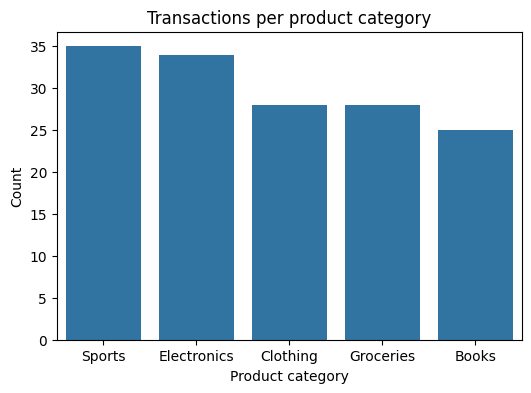

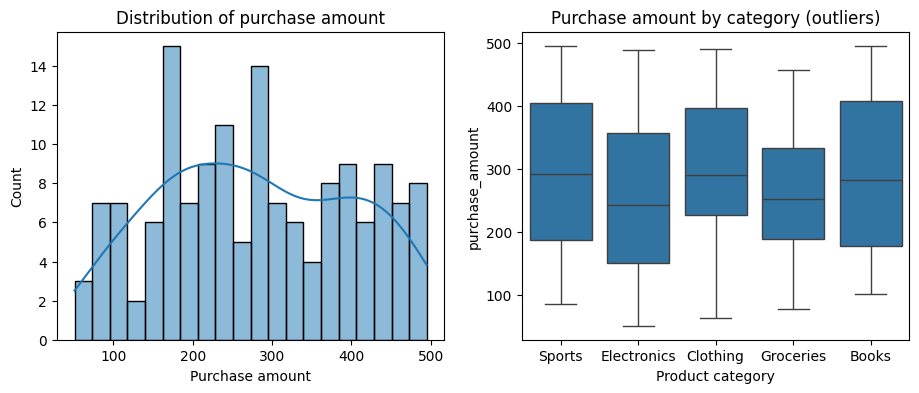

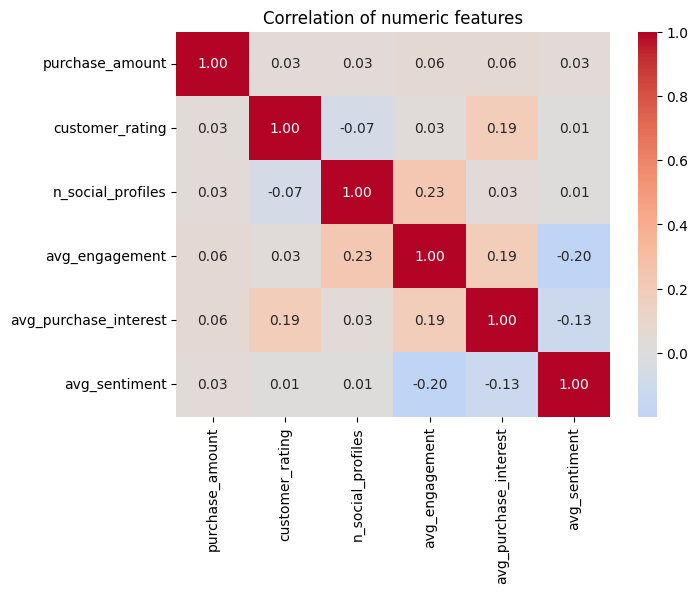

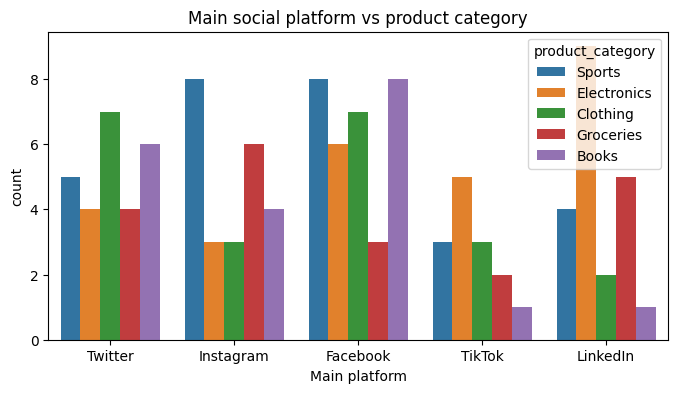

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

FIG_DIR = "/content/figures"      # in PyCharm: "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Plot 1: target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=merged, x="product_category", order=merged["product_category"].value_counts().index)
plt.title("Transactions per product category"); plt.xlabel("Product category"); plt.ylabel("Count")
plt.savefig(f"{FIG_DIR}/target_distribution.png", bbox_inches="tight"); plt.show()

# Plot 2: purchase amount distribution + outliers
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(merged["purchase_amount"], bins=20, kde=True, ax=ax[0])
ax[0].set_title("Distribution of purchase amount"); ax[0].set_xlabel("Purchase amount")
sns.boxplot(data=merged, x="product_category", y="purchase_amount", ax=ax[1])
ax[1].set_title("Purchase amount by category (outliers)"); ax[1].set_xlabel("Product category")
plt.savefig(f"{FIG_DIR}/purchase_amount.png", bbox_inches="tight"); plt.show()

# Plot 3: correlation heatmap of numeric columns
num_cols = ["purchase_amount", "customer_rating", "n_social_profiles",
            "avg_engagement", "avg_purchase_interest", "avg_sentiment"]
plt.figure(figsize=(7, 5))
sns.heatmap(merged[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features")
plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", bbox_inches="tight"); plt.show()

# Plot 4: social platform vs product category
plt.figure(figsize=(8, 4))
sns.countplot(data=merged.dropna(subset=["main_platform"]), x="main_platform", hue="product_category")
plt.title("Main social platform vs product category"); plt.xlabel("Main platform")
plt.savefig(f"{FIG_DIR}/platform_vs_category.png", bbox_inches="tight"); plt.show()

## 6. Exploratory data analysis

**Plot 1: Transactions per product category.** The five categories are fairly balanced, from Sports (about 35) to Books (about 25). No category dominates, so accuracy is a reasonable metric and no resampling is needed. Macro-F1 is reported alongside it.

**Plot 2: Purchase amount.** Amounts are spread broadly between about 50 and 500 with no single peak and no extreme tail. The boxplots show no outliers beyond the whiskers in any category, so nothing was removed or capped. Medians are similar across categories (about 240 to 295), so purchase amount alone is unlikely to separate categories.

**Plot 3: Correlation heatmap.** All correlations are weak. The largest are 0.23 (number of profiles vs. engagement), 0.19 (rating vs. purchase interest, and engagement vs. purchase interest) and -0.20 (engagement vs. sentiment). Nothing is high enough to cause multicollinearity, so all features were kept. Purchase amount is close to uncorrelated with everything.

**Plot 4: Main platform vs. product category.** Some bars stand out, for example Sports on Instagram and Facebook, but each bar holds only 1 to 9 transactions. No platform shows a clear preference for one category, and the visible differences are small counts that are likely noise.

**Overall:** the features show little linear signal for the target. This anticipates the modeling result in section 9.

In [28]:
df = merged.drop(columns=["_merge", "customer_id_legacy"]).copy()

# --- Missing values (each choice documented) ---
df["has_social_profile"] = df["n_social_profiles"].notna().astype(int)
df["rating_missing"] = df["customer_rating"].isna().astype(int)
df["customer_rating"] = df["customer_rating"].fillna(df["customer_rating"].median())
df["n_social_profiles"] = df["n_social_profiles"].fillna(0)
for c in ["avg_engagement", "avg_purchase_interest", "avg_sentiment"]:
    df[c] = df[c].fillna(df[c].median())
df["main_platform"] = df["main_platform"].fillna("Unknown")

# --- Per-customer behaviour (none of these use product_category, so no target leakage) ---
ref_date = df["purchase_date"].max() + pd.Timedelta(days=1)
g = df.groupby("customer_id")
df["customer_purchase_count"] = g["transaction_id"].transform("count")
df["customer_avg_spend"] = g["purchase_amount"].transform("mean")
df["customer_total_spend"] = g["purchase_amount"].transform("sum")
df["recency_days"] = (ref_date - g["purchase_date"].transform("max")).dt.days
df["amount_vs_customer_avg"] = df["purchase_amount"] / df["customer_avg_spend"]

# --- Date features ---
df["purchase_month"] = df["purchase_date"].dt.month
df["purchase_dayofweek"] = df["purchase_date"].dt.dayofweek

# --- Encode social platform ---
df = pd.get_dummies(df, columns=["main_platform"], prefix="platform", dtype=int)

print(df.shape)
print("nulls left:", df.isna().sum().sum())
print("unmatched customers:", merged.loc[merged["_merge"] == "left_only", "customer_id"].nunique(), "(expected 14)")
df.head()

os.makedirs("/content/processed", exist_ok=True)       # in PyCharm: "../data/processed"
df.to_csv(PROC_DIR / "merged_dataset.csv", index=False)

(150, 25)
nulls left: 0
unmatched customers: 14 (expected 14)


## 7. Feature engineering

**Missing values**
- `has_social_profile` (0/1) marks the 33 unmatched transactions; `n_social_profiles` is set to 0 for them.
- `rating_missing` (0/1) flags the 10 missing ratings, which are filled with the median.
- Missing `avg_engagement`, `avg_purchase_interest` and `avg_sentiment` are filled with the median; missing `main_platform` becomes `"Unknown"`.

**Per-customer behaviour** (none of these use `product_category`, so there is no target leakage)
- `customer_purchase_count`, `customer_avg_spend`, `customer_total_spend`
- `recency_days`: days between the customer's latest purchase and the day after the last purchase in the data
- `amount_vs_customer_avg`: this purchase relative to the customer's average

**Date features:** `purchase_month`, `purchase_dayofweek`

**Encoding:** `main_platform` is one-hot encoded (`platform_*`).

**Result:** 150 rows × 25 columns, no missing values, saved as `data/processed/merged_dataset.csv`.

In [29]:
import numpy as np, joblib
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from xgboost import XGBClassifier

# --- Features / target ---
drop_cols = ["product_category", "transaction_id", "customer_id", "purchase_date"]
X = df.drop(columns=drop_cols)
le = LabelEncoder()
y = le.fit_transform(df["product_category"])
groups = df["customer_id"]
print("features:", X.shape[1], "| classes:", list(le.classes_))

# --- Split by customer so no customer is on both sides ---
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
print("train/test rows:", len(X_tr), len(X_te),
      "| shared customers:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                             eval_metric="mlogloss", random_state=42),
}

# --- Test-set results ---
results = {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred, proba = m.predict(X_te), m.predict_proba(X_te)
    results[name] = {
        "accuracy": accuracy_score(y_te, pred),
        "f1_macro": f1_score(y_te, pred, average="macro"),
        "log_loss": log_loss(y_te, proba, labels=range(len(le.classes_))),
    }
print(pd.DataFrame(results).T.round(3))
print("random-guess accuracy ~", round(1 / len(le.classes_), 2))

# --- Cross-validation by customer (more reliable than one small split) ---
gkf = GroupKFold(n_splits=5)
for name, m in models.items():
    p = cross_val_predict(m, X, y, groups=groups, cv=gkf)
    print(f"{name} 5-fold grouped CV accuracy: {accuracy_score(y, p):.3f}")

features: 21 | classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']
train/test rows: 119 31 | shared customers: 0
                     accuracy  f1_macro  log_loss
Logistic Regression     0.129     0.099     1.959
Random Forest           0.194     0.150     1.690
XGBoost                 0.226     0.213     2.266
random-guess accuracy ~ 0.2
Logistic Regression 5-fold grouped CV accuracy: 0.193
Random Forest 5-fold grouped CV accuracy: 0.220
XGBoost 5-fold grouped CV accuracy: 0.260


In [30]:
from scipy.stats import chi2_contingency
ct = pd.crosstab(merged["main_platform"], merged["product_category"]) if "main_platform" in merged else \
     pd.crosstab(merged.merge(social_agg[["customer_id","main_platform"]], on="customer_id")["main_platform"], merged["product_category"])
chi2, p, dof, _ = chi2_contingency(ct)
print(f"chi-square p-value: {p:.3f}")   # p > 0.05 means no evidence platform and category are related

chi-square p-value: 0.345


## 8. Modeling approach

**Target:** `product_category` (5 classes: Books, Clothing, Electronics, Groceries, Sports). Random guessing gives about 20% accuracy.

**Leakage prevention:** the same customer appears in several rows, so a random split could place one customer's transactions on both the training and test sides and inflate scores. All evaluation therefore **splits by customer** (`GroupShuffleSplit` for the single split, `GroupKFold` for cross-validation). The single split has 0 shared customers between train and test.

**Metrics:** accuracy, macro-F1 and log-loss. A model that predicts class frequencies only (a "baseline") is included for comparison.

In [31]:
from sklearn.dummy import DummyClassifier

def cv_scores(model):
    proba = cross_val_predict(model, X, y, groups=groups, cv=GroupKFold(n_splits=5),
                              method="predict_proba")
    pred = proba.argmax(axis=1)
    return {"accuracy": accuracy_score(y, pred),
            "f1_macro": f1_score(y, pred, average="macro"),
            "log_loss": log_loss(y, proba)}

candidates = {
    "Baseline (class priors)": DummyClassifier(strategy="prior"),
    "Logistic Regression (C=0.05)": make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=1000)),
    "Random Forest (shallow)": RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=5, random_state=42),
    "XGBoost (regularized)": XGBClassifier(n_estimators=50, max_depth=2, learning_rate=0.05, subsample=0.8,
                                           colsample_bytree=0.8, min_child_weight=5,
                                           eval_metric="mlogloss", random_state=42),
}
res = pd.DataFrame({name: cv_scores(m) for name, m in candidates.items()}).T.round(3)
print(res)

                              accuracy  f1_macro  log_loss
Baseline (class priors)          0.173     0.094     1.636
Logistic Regression (C=0.05)     0.227     0.202     1.746
Random Forest (shallow)          0.200     0.154     1.649
XGBoost (regularized)            0.240     0.213     1.649


### Regularized models (customer-grouped 5-fold CV)

| Model | Accuracy | Macro-F1 | Log-loss |
|---|---|---|---|
| Baseline (class priors) | 0.173 | 0.094 | 1.636 |
| Logistic Regression (C=0.05) | 0.227 | 0.202 | 1.746 |
| Random Forest (shallow) | 0.200 | 0.154 | 1.649 |
| **XGBoost (regularized)** | **0.240** | **0.213** | 1.649 |

**Interpretation**
- Regularization removed the overconfidence (XGBoost log-loss fell from 2.27 to 1.65), but no model beats the baseline log-loss of 1.636.
- With 150 rows the standard error on accuracy is about ±3.5 points, so differences between models are within noise.
- **Conclusion:** `product_category` is not reliably predictable from the available features; performance is near the random-guess baseline. This matches the weak correlations in the EDA and is reported as an honest result rather than tuned further.

**Model choice:** XGBoost was selected for the highest accuracy and macro-F1, with log-loss tied for the lowest model value. The deployed model is trained by `src/train_product_model.py`, whose results are saved in `reports/product_model_metrics.csv`. Scores there differ slightly from this notebook because of environment differences, but in every run all models stay near the baseline.

In [32]:
BEST_NAME = "XGBoost (regularized)"      # <- change to your winner from cell 9
best_model = candidates[BEST_NAME].fit(X, y)     # final refit on all 150 rows

os.makedirs("/content/models", exist_ok=True)    # in PyCharm: "../models"
joblib.dump({"model": best_model, "label_encoder": le, "feature_names": list(X.columns)},
            "/content/models/product_model.joblib")

# the interface for teammate D: features in, (label, confidence) out
def predict_product(features: dict):
    row = pd.DataFrame([features]).reindex(columns=X.columns, fill_value=0)
    proba = best_model.predict_proba(row)[0]
    return le.inverse_transform([proba.argmax()])[0], float(proba.max())

print(predict_product(X.iloc[0].to_dict()))

('Sports', 0.5239165425300598)


## 9. Interface for the CLI

The deployed product model is called after face and voice verification succeed. Given a customer ID, `predict_product(customer_id)` in `src/predict.py` returns `(category, confidence)`. Confidence values are expected to be low (about 0.2 to 0.35), consistent with the weak signal above.